In [1]:
import pandas as pd

df = pd.read_csv("../data/kerala_water_quality_cleaned.csv")

In [2]:
df.shape

(1155, 21)

In [3]:
df.columns


Index(['_id', 'SlNo', 'Station', 'Agency', 'State LGD Code', 'State',
       'District LGD Code', 'District', 'Tehsil', 'River', 'Basin',
       'Tributary', 'Subtributary', 'SubSubtributary', 'Local River',
       'Latitude', 'Longitude', 'Data Acquisition Time',
       'Biochemical Oxygen Demand (mg/L)', 'Fecal Coliform (MPN/100mL)',
       'Total Coliform (MPN/100mL)'],
      dtype='str')

In [4]:
df["Station"].nunique()


129

In [5]:
df[[
    "Biochemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]].describe()

,Biochemical Oxygen Demand (mg/L),Fecal Coliform (MPN/100mL),Total Coliform (MPN/100mL)
count,1155.000000,1155.000000,1155.000000
mean,2.076797,660.211255,1328.386147
std,0.967988,2833.529324,7050.053488
min,1.100000,4.000000,12.000000
25%,1.800000,100.000000,620.000000
50%,1.900000,130.000000,620.000000
75%,2.000000,310.000000,620.000000
max,8.200000,70000.000000,200000.000000


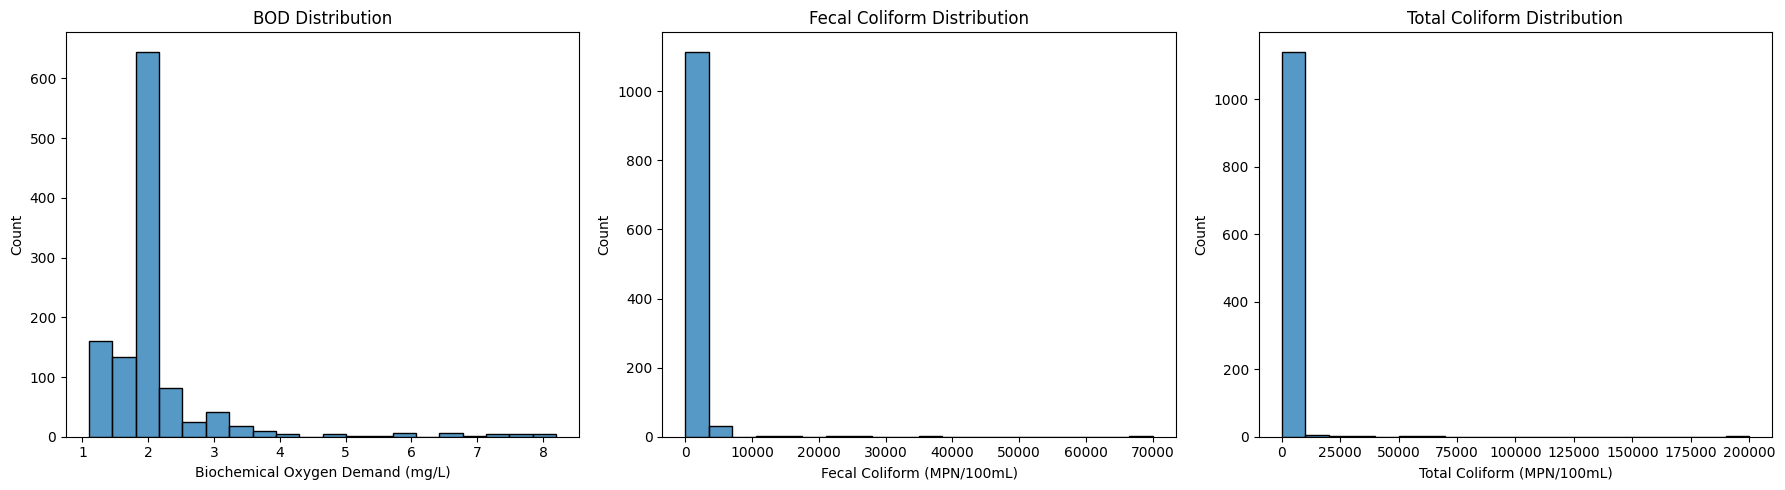

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["Biochemical Oxygen Demand (mg/L)"], bins=20, ax=axes[0])
axes[0].set_title("BOD Distribution")

sns.histplot(df["Fecal Coliform (MPN/100mL)"], bins=20, ax=axes[1])
axes[1].set_title("Fecal Coliform Distribution")

sns.histplot(df["Total Coliform (MPN/100mL)"], bins=20, ax=axes[2])
axes[2].set_title("Total Coliform Distribution")

plt.tight_layout()
plt.show()

In [7]:
district_bod = df.groupby("District")[
    "Biochemical Oxygen Demand (mg/L)"
].mean().sort_values(ascending=False)

district_bod

District
THIRUVANANTHAPURAM    3.403571
Alappuzha             2.128713
Kollam                2.095588
ERNAKULAM             2.094059
KOTTAYAM              2.000000
PATHANAMTHITTA        1.963636
PALAKKAD              1.901176
IDUKKI                1.858621
KOZHIKODE             1.853922
MALAPPURAM            1.825000
THRISSUR              1.816456
KANNUR                1.787273
KASARAGOD             1.785897
WAYANAD               1.672973
Name: Biochemical Oxygen Demand (mg/L), dtype: float64

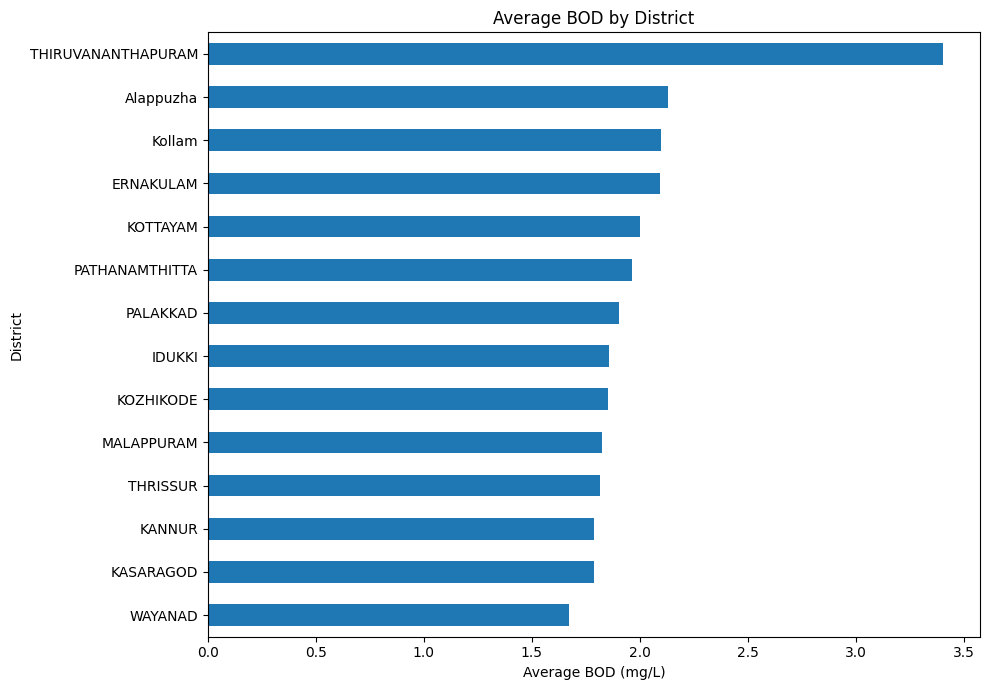

In [8]:
import matplotlib.pyplot as plt

district_bod.sort_values().plot(kind="barh", figsize=(10, 7))

plt.title("Average BOD by District")
plt.xlabel("Average BOD (mg/L)")
plt.ylabel("District")
plt.tight_layout()
plt.show()

In [9]:
district_fecal = df.groupby("District")[
    "Fecal Coliform (MPN/100mL)"
].mean().sort_values(ascending=False)

district_fecal

District
KOZHIKODE             3385.372549
IDUKKI                1057.586207
ERNAKULAM              868.628713
THIRUVANANTHAPURAM     648.035714
KOTTAYAM               497.307692
MALAPPURAM             487.533333
THRISSUR               327.101266
PATHANAMTHITTA         234.772727
PALAKKAD               215.541176
Alappuzha              122.940594
Kollam                 112.823529
KASARAGOD               85.294872
KANNUR                  69.309091
WAYANAD                 62.648649
Name: Fecal Coliform (MPN/100mL), dtype: float64

In [10]:
df["Station"].nunique()

129

In [11]:
df["Station"].value_counts()

Station
ACHANKOVIL AT CHENNITHULA                                      12
ACHANKOVIL AT KALLARAKADAVU PATHANAMTHITTA                     12
ACHANKOVIL AT PANDALAM (NEAR AYYAPPA TEMPLE) PATHANAMTHITTA    12
ACHANKOVIL AT THUMPAMON                                        12
ALAPPUZHA KERALA                                               12
                                                               ..
WELL AT VYTTILA ERNAKULAM DISTT.  KERALA                        2
WELL OF TEMPLE PARASSINIKADAVU KANNUR                           2
WELL AT CHERTHALA ALLEPPY KERALA                                1
WELL AT OLLUR (THRISSUR)                                        1
WELL AT PUNKUNNAM TRISSUR DISTT.  KERALA                        1
Name: count, Length: 129, dtype: int64

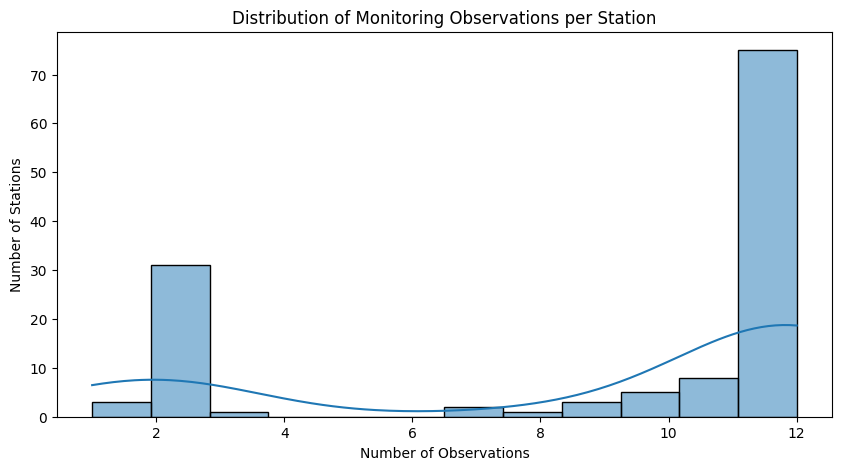

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

station_counts = df["Station"].value_counts()

plt.figure(figsize=(10, 5))

sns.histplot(station_counts, bins=12, kde=True)

plt.title("Distribution of Monitoring Observations per Station")
plt.xlabel("Number of Observations")
plt.ylabel("Number of Stations")

plt.show()

In [13]:
df["District"].value_counts()

District
ERNAKULAM             202
THIRUVANANTHAPURAM    112
KANNUR                110
KOZHIKODE             102
Alappuzha             101
PALAKKAD               85
THRISSUR               79
KASARAGOD              78
Kollam                 68
PATHANAMTHITTA         66
MALAPPURAM             60
WAYANAD                37
IDUKKI                 29
KOTTAYAM               26
Name: count, dtype: int64

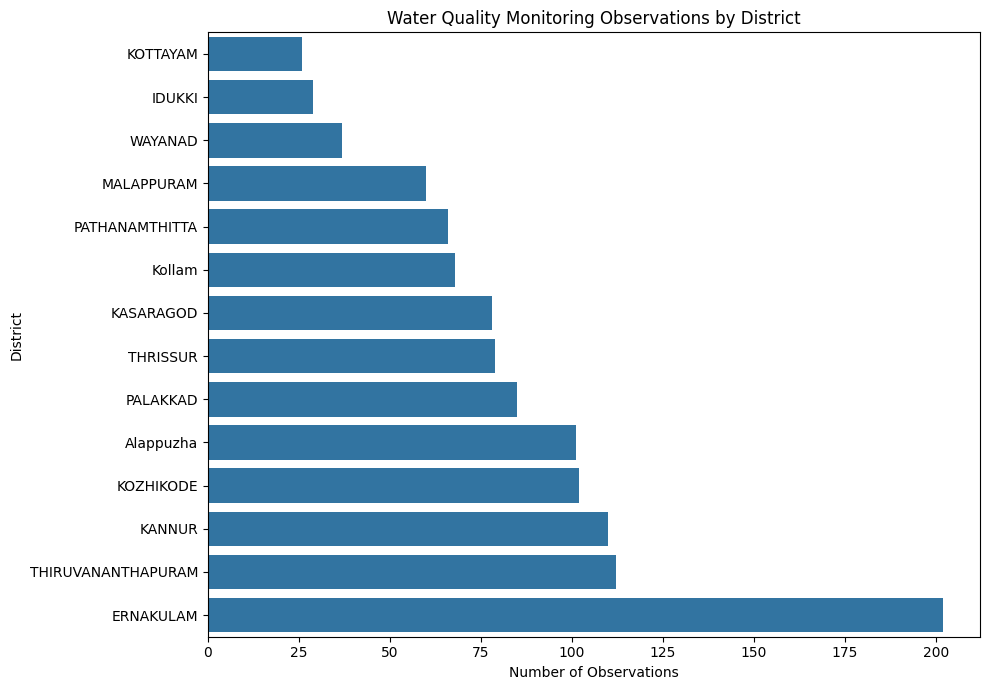

In [14]:

district_counts = df["District"].value_counts().sort_values()

plt.figure(figsize=(10, 7))

sns.barplot(x=district_counts.values, y=district_counts.index)

plt.title("Water Quality Monitoring Observations by District")
plt.xlabel("Number of Observations")
plt.ylabel("District")

plt.tight_layout()
plt.show()


In [15]:

print("Columns related to waterbody/location:")
print([
    col for col in df.columns
    if any(word in col.lower() for word in
           ["water", "river", "lake", "type", "station", "district"])
])


Columns related to waterbody/location:
['Station', 'District LGD Code', 'District', 'River', 'Local River']


In [20]:
df["Data Acquisition Time"] = pd.to_datetime(
    df["Data Acquisition Time"],
    errors="coerce"
)

print(df["Data Acquisition Time"].dtype)

datetime64[us]


In [17]:
print(df.columns.tolist())

['_id', 'SlNo', 'Station', 'Agency', 'State LGD Code', 'State', 'District LGD Code', 'District', 'Tehsil', 'River', 'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River', 'Latitude', 'Longitude', 'Data Acquisition Time', 'Biochemical Oxygen Demand (mg/L)', 'Fecal Coliform (MPN/100mL)', 'Total Coliform (MPN/100mL)']


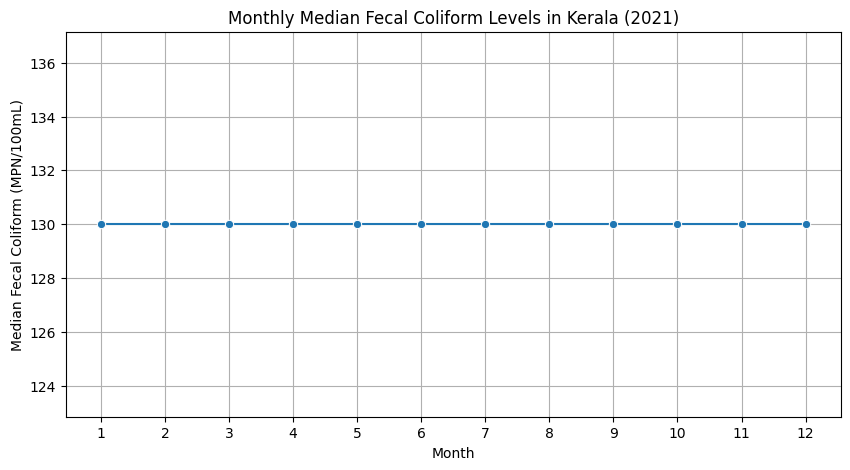

In [22]:

fc_time = df.dropna(
    subset=["Fecal Coliform (MPN/100mL)"]
).copy()

fc_time["Month"] = (
    fc_time["Data Acquisition Time"].dt.month
)

monthly_fc = fc_time.groupby("Month")[
    "Fecal Coliform (MPN/100mL)"
].median()

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_fc.index,
    y=monthly_fc.values,
    marker="o"
)

plt.title("Monthly Median Fecal Coliform Levels in Kerala (2021)")
plt.xlabel("Month")
plt.ylabel("Median Fecal Coliform (MPN/100mL)")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()



### Monthly Fecal Coliform Analysis

**Objective:** Investigate temporal variation in fecal contamination indicators
across water-quality monitoring observations in Kerala during 2021.

**Method:** Calculate monthly median Fecal Coliform concentrations.
The median was selected because FC measurements are strongly right-skewed
and contain extreme values.

**Observation:** The monthly median was 130 MPN/100mL for all 12 months.
However, monthly mean values varied considerably, and extreme measurements
were observed.

**Interpretation:** The identical monthly medians do not indicate that
fecal contamination remained constant. Repeated measurements at 130
influence the median, while higher observations contribute to variation
in the mean.

**Limitation:** Monthly statistics combine observations from different
monitoring locations. They do not necessarily represent changes at
the same waterbody over time.


In [23]:

fc_col = "Fecal Coliform (MPN/100mL)"

print("Overall FC value counts:")
print(df[fc_col].value_counts().head(15))

print("\nMonthly FC statistics:")
print(
    fc_time.groupby("Month")[fc_col]
    .agg(["count", "min", "median", "mean", "max"])
)


Overall FC value counts:
Fecal Coliform (MPN/100mL)
130.0     284
100.0      70
200.0      65
110.0      46
120.0      35
310.0      34
94.0       30
40.0       29
70.0       28
63.0       26
79.0       23
84.0       19
49.0       17
1400.0     16
400.0      15
Name: count, dtype: int64

Monthly FC statistics:
       count   min  median         mean      max
Month                                           
1         96  10.0   130.0   535.677083  11000.0
2         96  32.0   130.0   521.552083  17000.0
3         92  31.0   130.0   322.347826   4800.0
4        122   4.0   130.0   597.352459  24000.0
5         80  20.0   130.0   626.637500   6300.0
6         89  17.0   130.0   837.719101  17000.0
7         90  17.0   130.0   626.122222   6300.0
8         90  17.0   130.0   528.566667   4800.0
9         92  17.0   130.0   643.184783   6800.0
10       124  10.0   130.0   687.895161  38000.0
11        93  20.0   130.0   864.860215  25000.0
12        91  20.0   130.0  1153.879121  70000.0


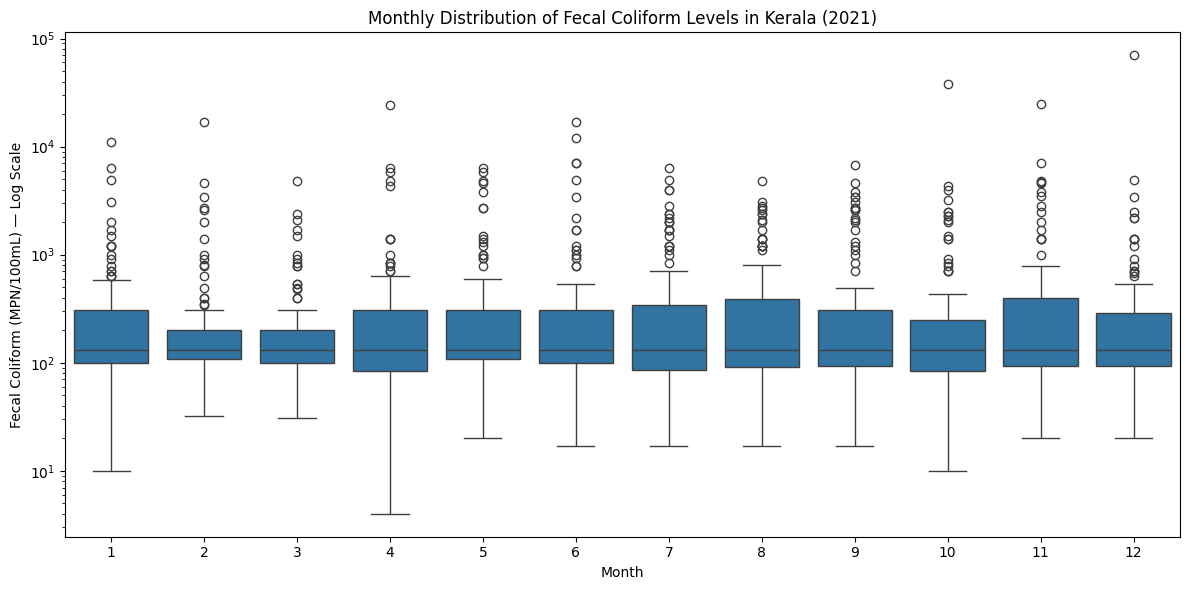

In [24]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=fc_time,
    x="Month",
    y="Fecal Coliform (MPN/100mL)"
)

plt.yscale("log")

plt.title("Monthly Distribution of Fecal Coliform Levels in Kerala (2021)")
plt.xlabel("Month")
plt.ylabel("Fecal Coliform (MPN/100mL) — Log Scale")

plt.tight_layout()
plt.show()



### Results and Interpretation

Monthly Fecal Coliform distributions were examined using boxplots with a logarithmic scale to account for the wide range of observed concentrations. Median values remained approximately 130 MPN/100mL across all months, while substantial variation and high-value outliers were observed. December recorded the highest concentration, approximately 70,000 MPN/100mL. These findings highlight variability in microbial water-quality measurements throughout the study period.


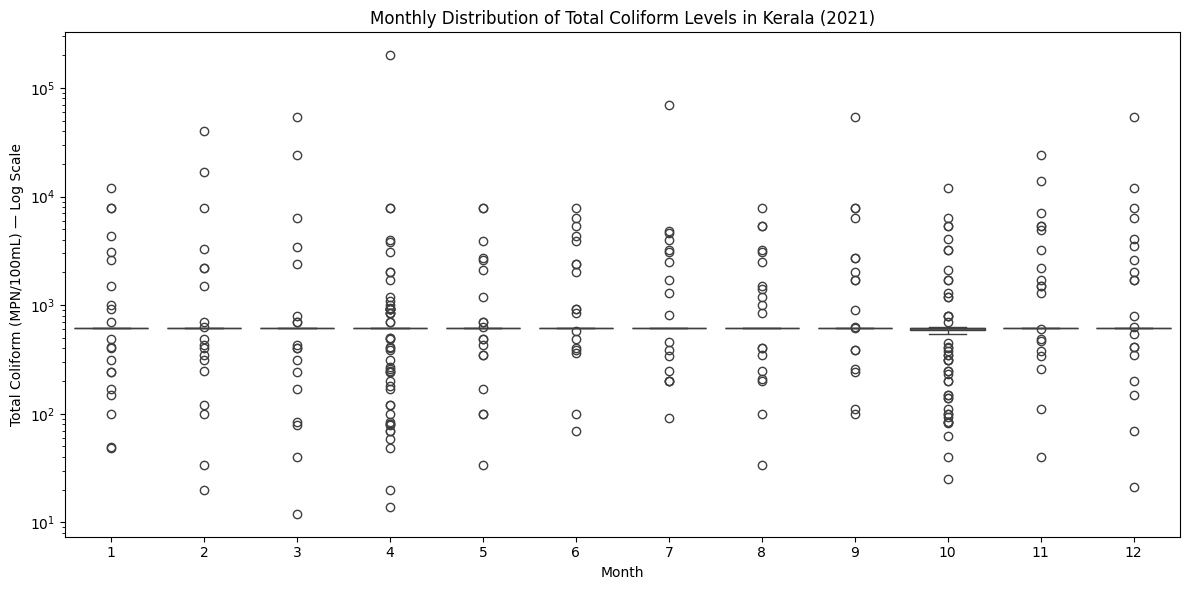

In [25]:

tc_time = df.dropna(
    subset=["Total Coliform (MPN/100mL)"]
).copy()

tc_time["Month"] = (
    tc_time["Data Acquisition Time"].dt.month
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=tc_time,
    x="Month",
    y="Total Coliform (MPN/100mL)"
)

plt.yscale("log")

plt.title("Monthly Distribution of Total Coliform Levels in Kerala (2021)")
plt.xlabel("Month")
plt.ylabel("Total Coliform (MPN/100mL) — Log Scale")

plt.tight_layout()
plt.show()



### Results and Interpretation

Monthly Total Coliform distributions were visualized using boxplots with a logarithmic scale to examine variability and extreme measurements. The distributions showed substantial variation, with observations extending across several orders of magnitude. April recorded the highest observed concentration, approximately 200,000 MPN/100mL. These findings indicate considerable variability among the available Total Coliform measurements throughout 2021.


In [26]:

parameters = [
    "Biochemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]

print(df[parameters].describe().T)


                                   count         mean          std   min  \
Biochemical Oxygen Demand (mg/L)  1155.0     2.076797     0.967988   1.1   
Fecal Coliform (MPN/100mL)        1155.0   660.211255  2833.529324   4.0   
Total Coliform (MPN/100mL)        1155.0  1328.386147  7050.053488  12.0   

                                    25%    50%    75%       max  
Biochemical Oxygen Demand (mg/L)    1.8    1.9    2.0       8.2  
Fecal Coliform (MPN/100mL)        100.0  130.0  310.0   70000.0  
Total Coliform (MPN/100mL)        620.0  620.0  620.0  200000.0  


In [27]:
print(df[parameters].isnull().sum())

Biochemical Oxygen Demand (mg/L)    0
Fecal Coliform (MPN/100mL)          0
Total Coliform (MPN/100mL)          0
dtype: int64


In [28]:
print("Dataset shape:", df.shape)

print("\nMissing values by column:")
print(df.isnull().sum())

Dataset shape: (1155, 21)

Missing values by column:
_id                                 0
SlNo                                0
Station                             0
Agency                              0
State LGD Code                      0
State                               0
District LGD Code                   0
District                            0
Tehsil                              0
River                               0
Basin                               0
Tributary                           0
Subtributary                        0
SubSubtributary                     0
Local River                         0
Latitude                            0
Longitude                           0
Data Acquisition Time               0
Biochemical Oxygen Demand (mg/L)    0
Fecal Coliform (MPN/100mL)          0
Total Coliform (MPN/100mL)          0
dtype: int64


In [29]:
raw_df = pd.read_csv("../data/kerala_water_quality.csv")

print(raw_df.shape)
print(raw_df.isnull().sum())

(1155, 22)
_id                                    0
SlNo                                   0
Station                                0
Agency                                 0
State LGD Code                         0
State                                  0
District LGD Code                      0
District                               0
Tehsil                                 0
River                                  0
Basin                                  0
Tributary                              0
Subtributary                           0
SubSubtributary                        0
Local River                            0
Latitude                               0
Longitude                              0
Data Acquisition Time                  0
Biochemical Oxygen Demand (mg/L)     499
Chemical Oxygen Demand (mg/L)       1155
Fecal Coliform (MPN/100mL)           272
Total Coliform (MPN/100mL)           862
dtype: int64


In [30]:
cleaned_df = pd.read_csv("../data/kerala_water_quality_cleaned.csv")

print(cleaned_df.shape)
print(cleaned_df.isnull().sum())

(1155, 21)
_id                                 0
SlNo                                0
Station                             0
Agency                              0
State LGD Code                      0
State                               0
District LGD Code                   0
District                            0
Tehsil                              0
River                               0
Basin                               0
Tributary                           0
Subtributary                        0
SubSubtributary                     0
Local River                         0
Latitude                            0
Longitude                           0
Data Acquisition Time               0
Biochemical Oxygen Demand (mg/L)    0
Fecal Coliform (MPN/100mL)          0
Total Coliform (MPN/100mL)          0
dtype: int64


In [31]:

measurement_cols = [
    "Biochemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]

print("Original dataset:")
print(raw_df[measurement_cols].describe())

print("\nCleaned dataset:")
print(cleaned_df[measurement_cols].describe())


Original dataset:
       Biochemical Oxygen Demand (mg/L)  Fecal Coliform (MPN/100mL)  \
count                        656.000000                  883.000000   
mean                           2.211280                  823.537939   
std                            1.268428                 3223.587417   
min                            1.100000                    4.000000   
25%                            1.500000                   79.000000   
50%                            1.900000                  130.000000   
75%                            2.400000                  490.000000   
max                            8.200000                70000.000000   

       Total Coliform (MPN/100mL)  
count                  293.000000  
mean                  3412.443686  
std                  13805.449667  
min                     12.000000  
25%                    240.000000  
50%                    620.000000  
75%                   2200.000000  
max                 200000.000000  

Cleaned dataset:


In [32]:
print(cleaned_df[measurement_cols].value_counts().head(10))

Biochemical Oxygen Demand (mg/L)  Fecal Coliform (MPN/100mL)  Total Coliform (MPN/100mL)
1.9                               100.0                       620.0                         28
                                  200.0                       620.0                         20
                                  110.0                       620.0                         19
                                  310.0                       620.0                         16
                                  94.0                        620.0                         14
                                  70.0                        620.0                         14
                                  120.0                       620.0                         13
                                  130.0                       620.0                         13
                                  79.0                        620.0                         11
                                  58.0                  


## Summary of Exploratory Data Analysis

The dataset contains 1,155 water-quality observations collected across 129 monitoring stations in Kerala during 2021. Exploratory analysis identified substantial missingness in BOD, Fecal Coliform, and Total Coliform measurements, while Chemical Oxygen Demand was entirely unavailable. The microbial parameters exhibited strongly right-skewed distributions with considerable variability and extreme observations. Preliminary temporal analysis revealed fluctuations in monthly BOD averages and substantial variation in microbial measurements. Monitoring observations were unevenly distributed across districts and stations.

These findings establish the need for systematic data preprocessing and validation before conducting refined water-quality analysis and pollution-risk assessment.


In [40]:
df = pd.read_csv("../data/kerala_water_quality.csv")

In [41]:

df["Data Acquisition Time"] = pd.to_datetime(
    df["Data Acquisition Time"],
    errors="coerce"
)


In [42]:
bod_time = df.dropna(
    subset=["Biochemical Oxygen Demand (mg/L)"]
).copy()

bod_time["Month"] = bod_time["Data Acquisition Time"].dt.month

monthly_bod = bod_time.groupby("Month")[
    "Biochemical Oxygen Demand (mg/L)"
].mean()


In [43]:
monthly_bod

Month
1.0     2.181081
2.0     1.981633
3.0     2.396296
4.0     2.020408
5.0     2.103390
6.0     2.564444
7.0     2.329730
8.0     2.525641
9.0     2.388889
10.0    1.947826
11.0    2.050000
12.0    2.775000
Name: Biochemical Oxygen Demand (mg/L), dtype: float64

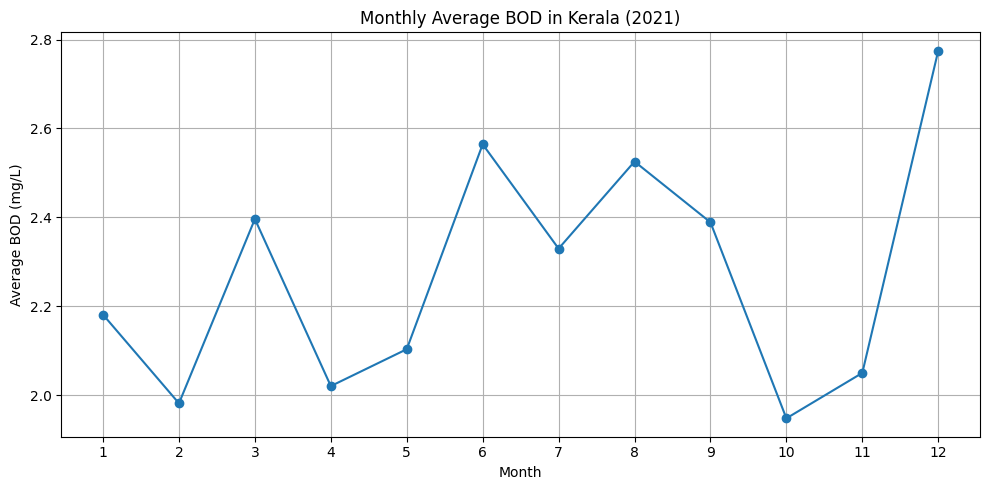

In [44]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_bod.index,
    monthly_bod.values,
    marker="o"
)

plt.title("Monthly Average BOD in Kerala (2021)")
plt.xlabel("Month")
plt.ylabel("Average BOD (mg/L)")
plt.xticks(range(1, 13))
plt.grid(True)

plt.tight_layout()
plt.show()



### Monthly BOD Analysis

Monthly average BOD values fluctuated during 2021, ranging approximately from 1.95 mg/L in October to 2.78 mg/L in December. June and August also recorded relatively higher averages. No consistent increasing or decreasing trend was observed. These results describe the available measurements and may be influenced by differences in monitoring-station coverage across months.


In [45]:
fc_time = df.dropna(
    subset=["Fecal Coliform (MPN/100mL)"]
).copy()

fc_time["Month"] = fc_time["Data Acquisition Time"].dt.month

monthly_fc = fc_time.groupby("Month")[
    "Fecal Coliform (MPN/100mL)"
].median()

monthly_fc

Month
1.0     110.0
2.0     150.0
3.0     120.0
4.0     120.0
5.0     100.0
6.0     170.0
7.0     145.0
8.0     105.0
9.0     160.0
10.0    120.0
11.0    300.0
12.0    185.0
Name: Fecal Coliform (MPN/100mL), dtype: float64

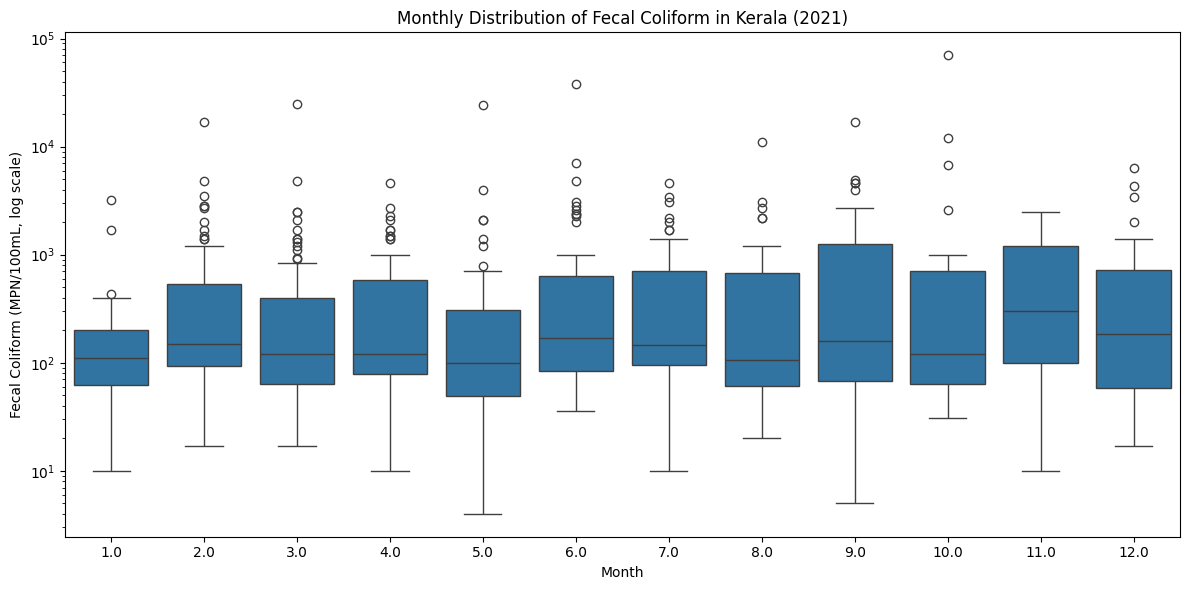

In [46]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=fc_time,
    x="Month",
    y="Fecal Coliform (MPN/100mL)"
)

plt.yscale("log")
plt.title("Monthly Distribution of Fecal Coliform in Kerala (2021)")
plt.xlabel("Month")
plt.ylabel("Fecal Coliform (MPN/100mL, log scale)")
plt.tight_layout()
plt.show()



### Monthly Fecal Coliform Analysis

The monthly boxplot reveals substantial variability in Fecal Coliform measurements throughout 2021. Median concentrations generally remained within approximately 100–200 MPN/100mL, although November showed a comparatively higher median. High-value observations occurred in every month, including an extreme observation of approximately 70,000 MPN/100mL in October. The logarithmic scale was used to represent the wide range of measurements. These patterns require further investigation during refined EDA.


In [47]:

tc_time = df.dropna(
    subset=["Total Coliform (MPN/100mL)"]
).copy()

tc_time["Month"] = tc_time["Data Acquisition Time"].dt.month


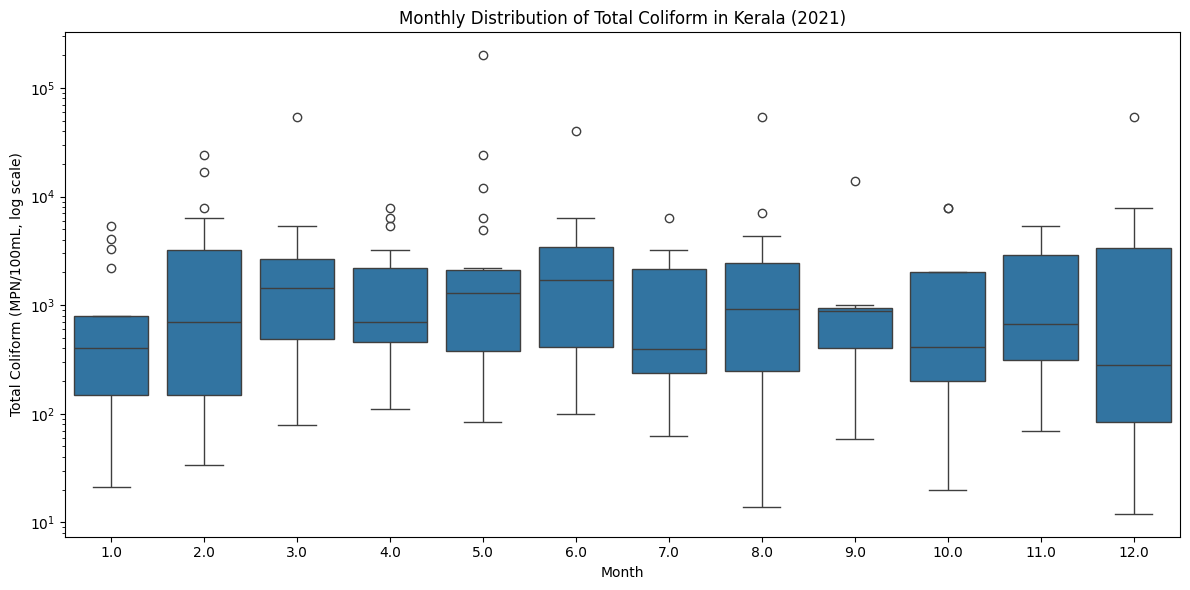

In [48]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=tc_time,
    x="Month",
    y="Total Coliform (MPN/100mL)"
)

plt.yscale("log")
plt.title("Monthly Distribution of Total Coliform in Kerala (2021)")
plt.xlabel("Month")
plt.ylabel("Total Coliform (MPN/100mL, log scale)")
plt.tight_layout()
plt.show()



### Monthly Total Coliform Analysis

The monthly boxplot indicates considerable variability in Total Coliform measurements throughout 2021. March, May, and June exhibited comparatively higher median concentrations, while January and July showed lower medians. Extreme observations were present in several months, including a measurement exceeding 100,000 MPN/100mL in May. The logarithmic scale helps visualize the wide range of values. Since approximately 74.6% of TC measurements are missing, these findings represent only the available observations and require cautious interpretation.
